In [7]:

import pandas as pd
import numpy as np
import re

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# 1. Read the uploaded CSV
df = pd.read_csv("surat_uncleaned.csv")

# 2. Clean column names and remove duplicates
df.columns = df.columns.str.strip()
df = df.drop_duplicates().copy()

# 3. Convert price into lakhs
def convert_price(value):
    if pd.isna(value):
        return np.nan

    value = str(value).lower().replace(",", "").replace("₹", "").strip()
    match = re.search(r"(\d+(?:\.\d+)?)", value)

    if not match:
        return np.nan

    number = float(match.group(1))

    if "crore" in value or "cr" in value:
        return number * 100
    elif "lakh" in value or "lac" in value:
        return number

    return np.nan

df["price"] = df["price"].apply(convert_price)
df = df.dropna(subset=["price"]).copy()

# 4. Convert square feet into numeric values
df["square_feet"] = pd.to_numeric(
    df["square_feet"].astype(str)
    .str.replace(",", "", regex=False)
    .str.extract(r"(\d+(?:\.\d+)?)", expand=False),
    errors="coerce"
)

# 5. Extract floor and total floors
floor_info = df["floor"].astype(str).str.extract(
    r"^\s*(\d+)\s+out of\s+(\d+)",
    flags=re.IGNORECASE
)

df["floor_number"] = pd.to_numeric(floor_info[0], errors="coerce")
df["total_floors"] = pd.to_numeric(floor_info[1], errors="coerce")

# 6. Select features and target
X = df[[
    "square_feet",
    "areaWithType",
    "transaction",
    "status",
    "floor_number",
    "total_floors",
    "furnishing",
    "facing"
]].copy()

y = df["price"].copy()

# 7. Identify numerical and categorical columns
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

# 8. Create preprocessing pipeline
preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

# 9. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 10. Fit on training data and transform both sets
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print("Original dataset:", df.shape)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Missing values in target:", y.isna().sum())
print("Preprocessing completed successfully!")


Original dataset: (4244, 13)
Training data: (3395, 381)
Testing data: (849, 381)
Missing values in target: 0
Preprocessing completed successfully!


LINEAR SVM TO PREDICT THE PRICE FLATS

In [8]:

from sklearn.svm import LinearSVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# 1. Create Linear SVM model
model = LinearSVR(
    C=1.0,
    max_iter=50000,
    random_state=42
)

# 2. Train the model
model.fit(X_train, y_train)

# 3. Make predictions
y_pred = model.predict(X_test)

# 4. Evaluate the model
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

# 5. Compare actual and predicted prices
results = pd.DataFrame({
    "Actual Price (Lakhs)": y_test.values,
    "Predicted Price (Lakhs)": y_pred
})

print("\nActual vs Predicted Prices:")
print(results.head(10).round(2))


MAE: 57.695758623874646
RMSE: 120.45085080399754
R2 Score: 0.23079237114418516

Actual vs Predicted Prices:
   Actual Price (Lakhs)  Predicted Price (Lakhs)
0                  68.0                    79.86
1                 315.0                   145.54
2                 405.0                   131.46
3                  24.0                    56.57
4                  81.0                    35.37
5                  35.0                    34.20
6                  69.5                    69.53
7                  30.0                    26.11
8                  51.7                   100.36
9                 190.0                   124.41


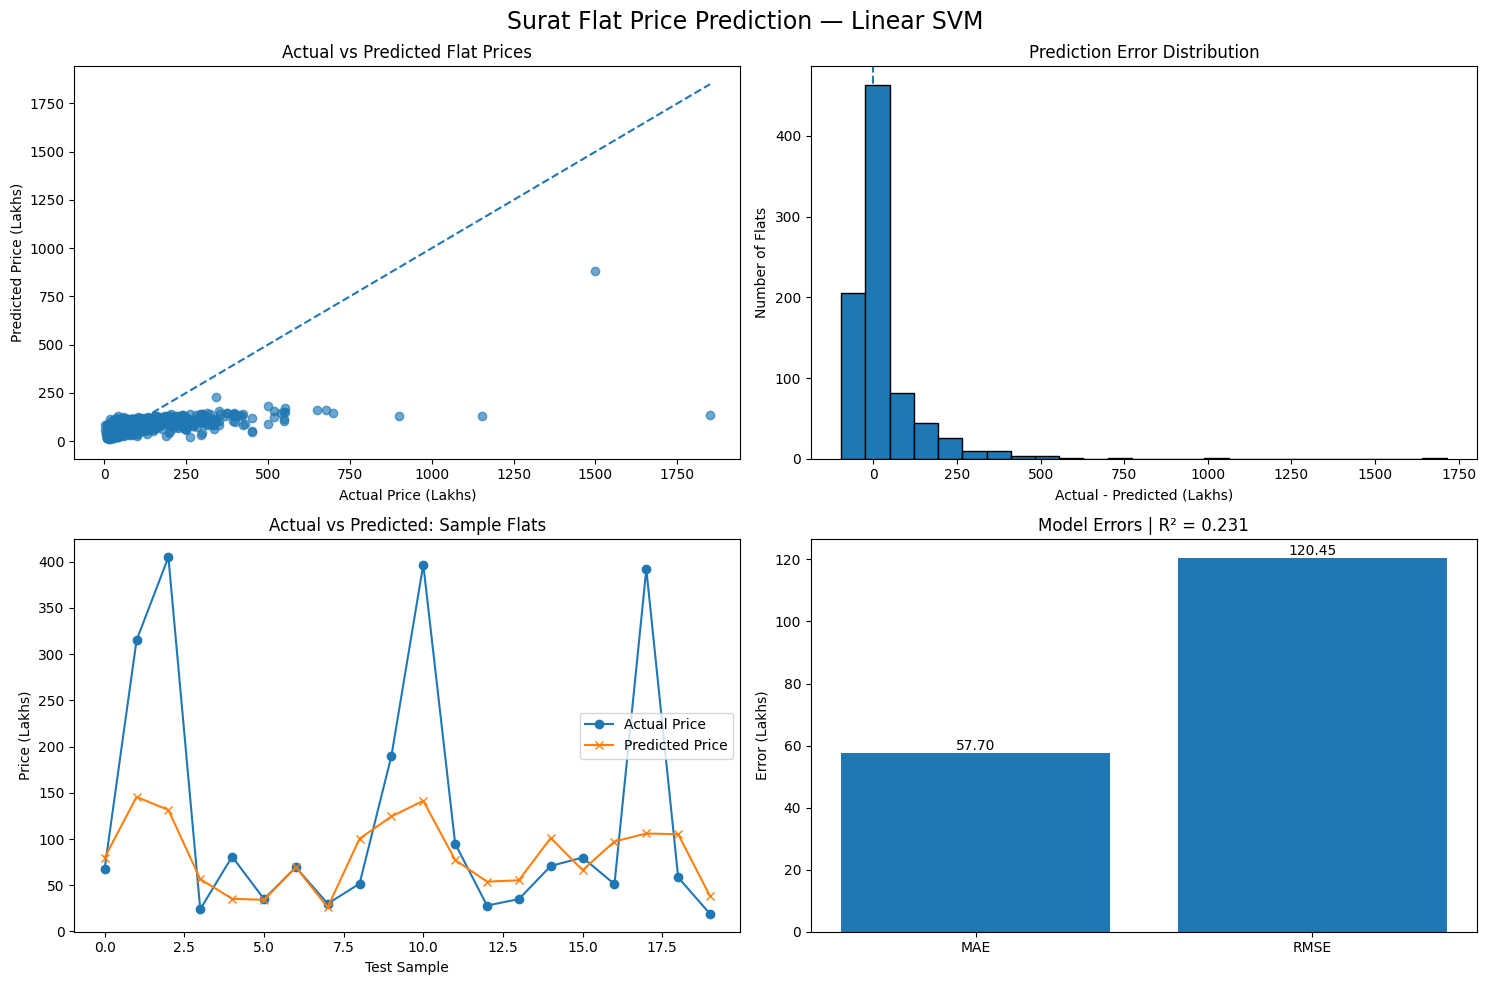

MAE:      57.70 lakhs
RMSE:     120.45 lakhs
R² Score: 0.2308


In [9]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

actual = np.asarray(y_test).ravel()
predicted = np.asarray(y_pred).ravel()
errors = actual - predicted

# Create a 2x2 dashboard
fig, ax = plt.subplots(2, 2, figsize=(15, 10))

# 1. Actual vs Predicted Prices
ax[0, 0].scatter(actual, predicted, alpha=0.65)
low = min(actual.min(), predicted.min())
high = max(actual.max(), predicted.max())
ax[0, 0].plot([low, high], [low, high], linestyle="--")
ax[0, 0].set_title("Actual vs Predicted Flat Prices")
ax[0, 0].set_xlabel("Actual Price (Lakhs)")
ax[0, 0].set_ylabel("Predicted Price (Lakhs)")

# 2. Prediction Error Distribution
ax[0, 1].hist(errors, bins=25, edgecolor="black")
ax[0, 1].axvline(0, linestyle="--")
ax[0, 1].set_title("Prediction Error Distribution")
ax[0, 1].set_xlabel("Actual - Predicted (Lakhs)")
ax[0, 1].set_ylabel("Number of Flats")

# 3. First 20 Test Predictions
n = min(20, len(actual))
positions = np.arange(n)

ax[1, 0].plot(positions, actual[:n], marker="o",
              label="Actual Price")
ax[1, 0].plot(positions, predicted[:n], marker="x",
              label="Predicted Price")
ax[1, 0].set_title("Actual vs Predicted: Sample Flats")
ax[1, 0].set_xlabel("Test Sample")
ax[1, 0].set_ylabel("Price (Lakhs)")
ax[1, 0].legend()

# 4. Model Performance Metrics
ax[1, 1].bar(
    ["MAE", "RMSE"],
    [mae, rmse]
)
ax[1, 1].set_title(f"Model Errors | R² = {r2:.3f}")
ax[1, 1].set_ylabel("Error (Lakhs)")

for i, value in enumerate([mae, rmse]):
    ax[1, 1].text(i, value, f"{value:.2f}",
                  ha="center", va="bottom")

fig.suptitle("Surat Flat Price Prediction — Linear SVM",
             fontsize=17)
plt.tight_layout()
plt.show()

# Print the metrics
print(f"MAE:      {mae:.2f} lakhs")
print(f"RMSE:     {rmse:.2f} lakhs")
print(f"R² Score: {r2:.4f}")


NON LINEAR SVM


NON-LINEAR SVM (RBF)
-------------------
MAE: 56.24 lakhs
RMSE: 124.49 lakhs
R2 Score: 0.1784

Sample predictions:
   Actual Price (Lakhs)  Predicted Price (Lakhs)
0                  68.0                    81.27
1                 315.0                   177.36
2                 405.0                   151.15
3                  24.0                    63.69
4                  81.0                    37.94
5                  35.0                    37.72
6                  69.5                    62.42
7                  30.0                    28.01
8                  51.7                   113.96
9                 190.0                   139.20


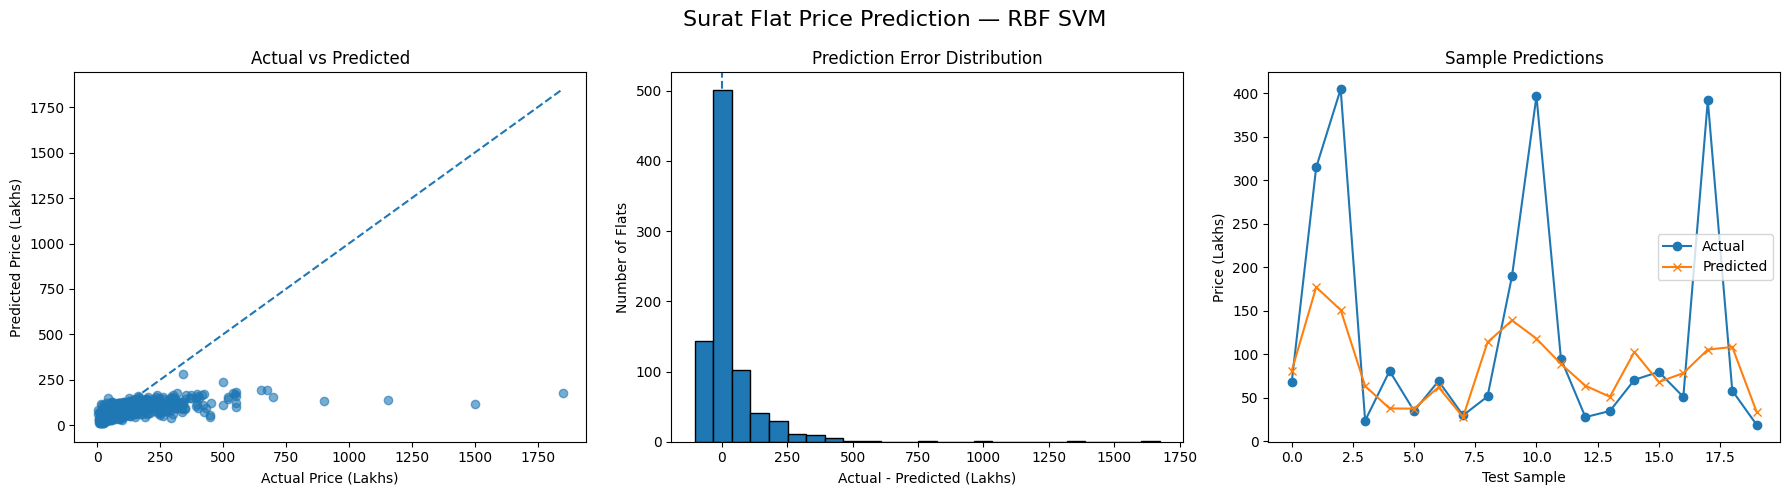

In [10]:

from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Create RBF SVM model
model = SVR(
    kernel="rbf",
    C=10,
    gamma="scale",
    epsilon=0.1
)

# 2. Train the model
model.fit(X_train, y_train)

# 3. Make predictions
y_pred = model.predict(X_test)

# 4. Evaluate model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("NON-LINEAR SVM (RBF)")
print("-------------------")
print(f"MAE: {mae:.2f} lakhs")
print(f"RMSE: {rmse:.2f} lakhs")
print(f"R2 Score: {r2:.4f}")

# 5. Compare actual vs predicted prices
results = pd.DataFrame({
    "Actual Price (Lakhs)": np.asarray(y_test),
    "Predicted Price (Lakhs)": y_pred
})

print("\nSample predictions:")
print(results.head(10).round(2))

# 6. Visualization dashboard
actual = np.asarray(y_test)
errors = actual - y_pred

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# Actual vs predicted
ax[0].scatter(actual, y_pred, alpha=0.6)
low = min(actual.min(), y_pred.min())
high = max(actual.max(), y_pred.max())
ax[0].plot([low, high], [low, high], "--")
ax[0].set_title("Actual vs Predicted")
ax[0].set_xlabel("Actual Price (Lakhs)")
ax[0].set_ylabel("Predicted Price (Lakhs)")

# Error distribution
ax[1].hist(errors, bins=25, edgecolor="black")
ax[1].axvline(0, linestyle="--")
ax[1].set_title("Prediction Error Distribution")
ax[1].set_xlabel("Actual - Predicted (Lakhs)")
ax[1].set_ylabel("Number of Flats")

# First 20 predictions
n = min(20, len(actual))
ax[2].plot(actual[:n], marker="o", label="Actual")
ax[2].plot(y_pred[:n], marker="x", label="Predicted")
ax[2].set_title("Sample Predictions")
ax[2].set_xlabel("Test Sample")
ax[2].set_ylabel("Price (Lakhs)")
ax[2].legend()

fig.suptitle("Surat Flat Price Prediction — RBF SVM", fontsize=16)
plt.tight_layout()
plt.show()


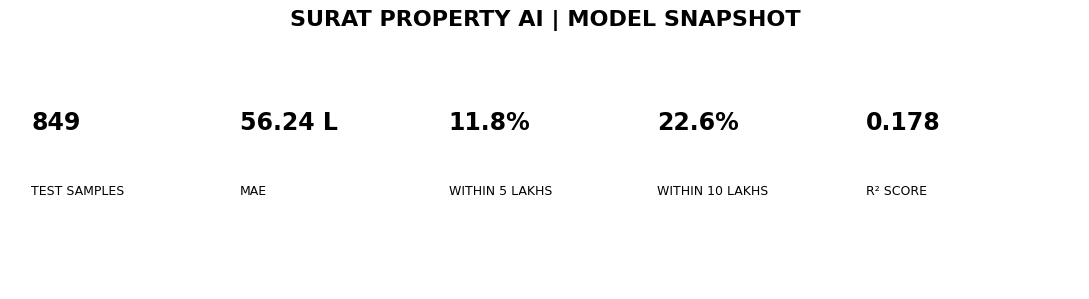

BEST PREDICTIONS
     Actual  Predicted  Absolute Error
37     27.5      27.61            0.11
694    50.0      49.89            0.11
665    91.0      90.85            0.15
609   115.0     114.76            0.24
367    40.0      40.25            0.25

WORST PREDICTIONS
     Actual  Predicted  Absolute Error
218  1850.0     175.86         1674.14
180  1500.0     117.66         1382.34
284  1155.0     137.66         1017.34
730   900.0     134.04          765.96
612   700.0     153.02          546.98


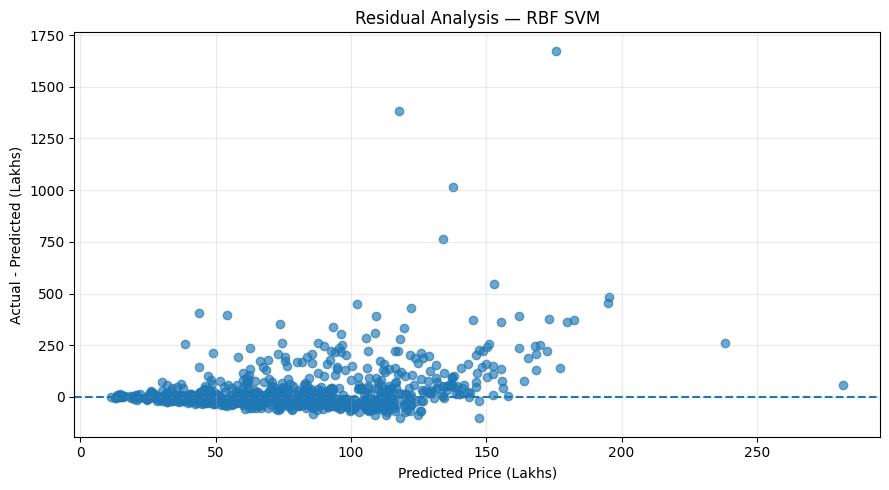

In [11]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

actual = np.asarray(y_test).ravel()
predicted = np.asarray(y_pred).ravel()
errors = actual - predicted

# 1. Prediction accuracy bands
abs_error = np.abs(errors)
within_5 = np.mean(abs_error <= 5) * 100
within_10 = np.mean(abs_error <= 10) * 100
within_20 = np.mean(abs_error <= 20) * 100

# 2. KPI dashboard
fig, ax = plt.subplots(figsize=(11, 3))
ax.axis("off")

kpis = [
    ("TEST SAMPLES", f"{len(actual)}"),
    ("MAE", f"{np.mean(abs_error):.2f} L"),
    ("WITHIN 5 LAKHS", f"{within_5:.1f}%"),
    ("WITHIN 10 LAKHS", f"{within_10:.1f}%"),
    ("R² SCORE", f"{r2_score(y_test, y_pred):.3f}")
]

for i, (label, value) in enumerate(kpis):
    x = 0.02 + i * 0.195
    ax.text(x, 0.68, value, transform=ax.transAxes,
            fontsize=17, fontweight="bold")
    ax.text(x, 0.40, label, transform=ax.transAxes,
            fontsize=9)

plt.suptitle("SURAT PROPERTY AI | MODEL SNAPSHOT",
             fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

# 3. Best vs worst predictions
results = pd.DataFrame({
    "Actual": actual,
    "Predicted": predicted,
    "Absolute Error": abs_error
})

print("BEST PREDICTIONS")
print(results.nsmallest(5, "Absolute Error").round(2))

print("\nWORST PREDICTIONS")
print(results.nlargest(5, "Absolute Error").round(2))

# 4. Residual plot
plt.figure(figsize=(9, 5))
plt.scatter(predicted, errors, alpha=0.65)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Price (Lakhs)")
plt.ylabel("Actual - Predicted (Lakhs)")
plt.title("Residual Analysis — RBF SVM")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
